# AI Usage Impact Analysis
## Notebook 2: Exploratory Data Analysis (EDA)

In [62]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt
from pathlib import Path
from scipy import stats

In [63]:
df = pd.read_csv("../Data/processed/cleaned_data.csv")

# every plot is saved in this folder (used later in the README)
IMG = "../images/"
Path(IMG).mkdir(exist_ok=True)

df.head()

,User_ID,Age,Gender,Country,User_Type,Education_Level,Profession,Monthly_Income,AI_Tool,AI_Purpose,...,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Would_Recommend,Age_Edu_Mismatch,Profession_Group,Plan,Age_Group,Usage_Level,Time_Saved_Ratio
0,U0269,30,Male,United Kingdom,Professional,Master's,Business Analyst,5421.0,ChatGPT,Office Work,...,7.0,3.9,7.3,Yes,0,Business & Admin,Free,26-35,Moderate,0.278571
1,U0217,30,Male,United States,Professional,Bachelor's,Customer Support Specialist,8903.0,ChatGPT,Customer Support,...,9.0,11.4,8.4,Yes,0,Customer Support,Free,26-35,Very Heavy,0.285714
2,U0152,17,Male,Canada,Student,Unknown,Computer Science Student,402.0,ChatGPT,Coding,...,4.0,5.2,6.7,No,0,Software & Data,Paid,Under 18,Light,0.742857
3,U0264,35,Female,Brazil,Professional,Bachelor's,Desenvolvedora de Software / Software Developer,1367.0,Meta AI,Coding,...,5.0,6.4,9.6,Maybe,0,Software & Data,Paid,26-35,Moderate,0.537815
4,U0263,19,Female,Canada,Student,Undergraduate,Biology Student,438.0,Perplexity AI,Unknown,...,7.0,9.2,6.2,Yes,0,Science & Education,Free,18-25,Heavy,0.320557


In [64]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 288 entries, 0 to 287
Data columns (total 25 columns):
 #   Column                       Non-Null Count  Dtype  
---  ------                       --------------  -----  
 0   User_ID                      288 non-null    str    
 1   Age                          288 non-null    int64  
 2   Gender                       288 non-null    str    
 3   Country                      288 non-null    str    
 4   User_Type                    288 non-null    str    
 5   Education_Level              288 non-null    str    
 6   Profession                   288 non-null    str    
 7   Monthly_Income               288 non-null    float64
 8   AI_Tool                      288 non-null    str    
 9   AI_Purpose                   288 non-null    str    
 10  AI_Usage_Hours_Per_Day       288 non-null    float64
 11  Tasks_Performed              288 non-null    str    
 12  Monthly_AI_Cost              288 non-null    float64
 13  Productivity_Score           28

In [65]:
df.describe()

,Age,Monthly_Income,AI_Usage_Hours_Per_Day,Monthly_AI_Cost,Productivity_Score,Accuracy_Rating,Satisfaction_Score,Time_Saved_Hours_Per_Week,Work_or_Study_Hours_Per_Day,Age_Edu_Mismatch,Time_Saved_Ratio
count,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000,288.000000
mean,29.406250,1435.194444,2.845833,9.496528,5.223611,3.444444,6.128472,5.781944,7.207292,0.020833,0.326014
std,10.738817,2063.299561,2.129660,13.742530,1.777521,0.845383,1.507526,4.045062,1.813571,0.143075,0.197124
min,16.000000,0.000000,0.500000,0.000000,1.600000,2.000000,3.000000,0.000000,2.100000,0.000000,0.000000
25%,22.000000,118.000000,1.375000,0.000000,4.000000,3.000000,5.000000,2.875000,6.100000,0.000000,0.214286
50%,26.000000,523.500000,2.000000,0.000000,5.000000,4.000000,6.000000,5.000000,7.200000,0.000000,0.289133
75%,35.000000,1791.750000,3.900000,20.000000,6.200000,4.000000,7.000000,7.500000,8.325000,0.000000,0.385714
max,64.000000,10311.000000,9.900000,100.000000,10.000000,5.000000,10.000000,19.400000,12.400000,1.000000,1.204082


# *First: Categorical Analysis*

In [66]:
df['User_Type'].value_counts()

User_Type
Student         151
Professional    137
Name: count, dtype: int64

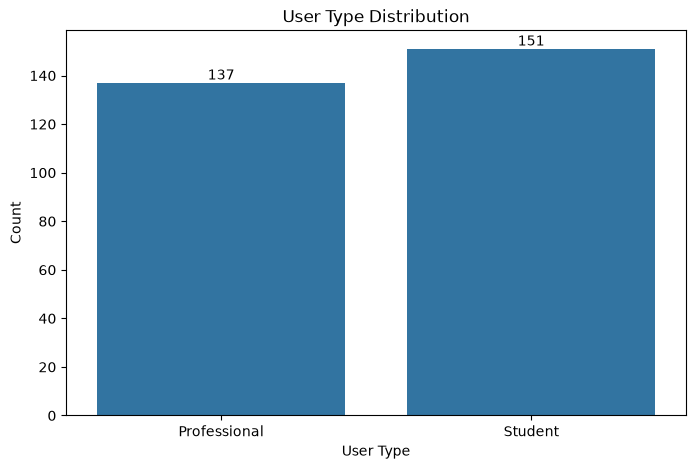

In [67]:
plt.figure(figsize=(8,5))

ax = sns.countplot(data=df, x='User_Type')
ax.bar_label(ax.containers[0])

plt.title("User Type Distribution")
plt.xlabel("User Type")
plt.ylabel("Count")

plt.savefig(IMG + "01_user_type.png", bbox_inches="tight")
plt.show()

In [68]:
df['AI_Tool'].value_counts(dropna=True)

AI_Tool
ChatGPT              119
Google Gemini         39
Microsoft Copilot     33
Claude                31
Perplexity AI         23
Grammarly             14
Meta AI               10
Unknown               10
DeepSeek               9
Name: count, dtype: int64

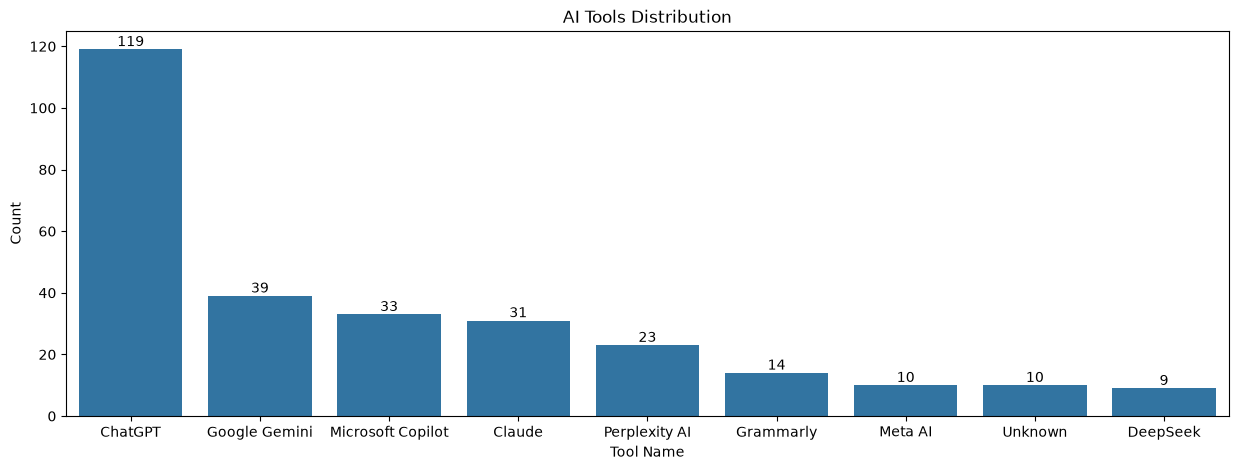

In [69]:
plt.figure(figsize=(15,5))

ax = sns.countplot(data=df, x='AI_Tool', order=df['AI_Tool'].value_counts().index)
ax.bar_label(ax.containers[0])

plt.title("AI Tools Distribution")
plt.xlabel("Tool Name")
plt.ylabel("Count")

plt.savefig(IMG + "02_ai_tools.png", bbox_inches="tight")
plt.show()

In [70]:
df['AI_Purpose'].value_counts()

AI_Purpose
Coding              65
Writing             49
Studying            39
Research            38
Content Creation    28
Data Analysis       25
Customer Support    20
Unknown             13
Office Work         11
Name: count, dtype: int64

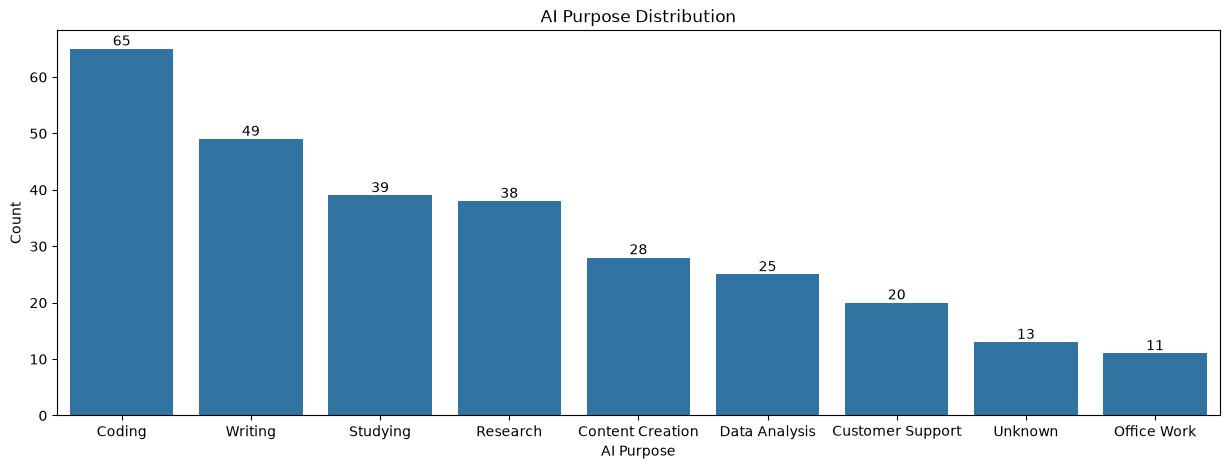

In [71]:
plt.figure(figsize=(15,5))

ax = sns.countplot(data=df, x='AI_Purpose', order=df['AI_Purpose'].value_counts().index)
ax.bar_label(ax.containers[0])

plt.title("AI Purpose Distribution")
plt.xlabel("AI Purpose")
plt.ylabel("Count")

plt.savefig(IMG + "03_ai_purpose.png", bbox_inches="tight")
plt.show()

In [72]:
df['Profession_Group'].value_counts()

Profession_Group
Software & Data        91
Science & Education    64
Content & Media        47
Business & Admin       21
Customer Support       17
Other                  17
Engineering            17
Unknown                14
Name: count, dtype: int64

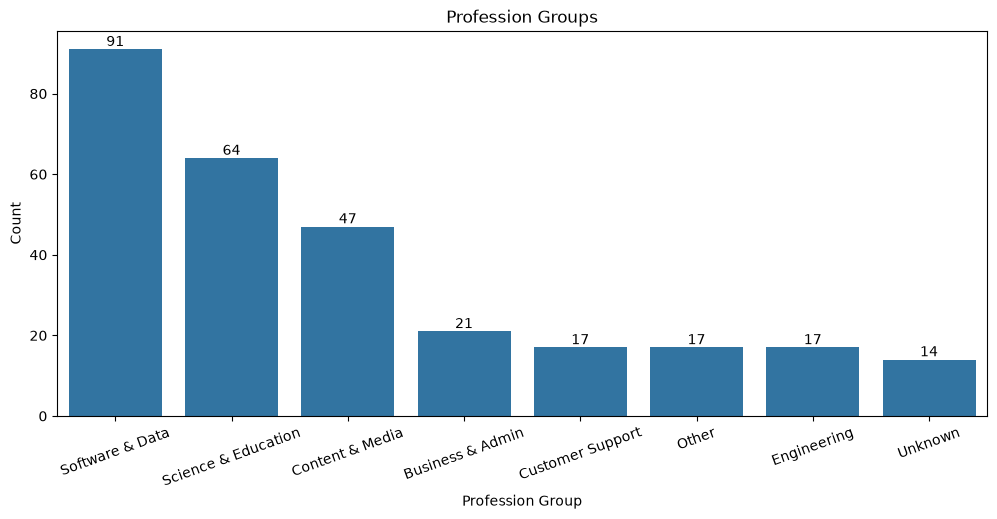

In [73]:
plt.figure(figsize=(12,5))

ax = sns.countplot(data=df, x='Profession_Group', order=df['Profession_Group'].value_counts().index)
ax.bar_label(ax.containers[0])

plt.title("Profession Groups")
plt.xlabel("Profession Group")
plt.ylabel("Count")
plt.xticks(rotation=20)

plt.savefig(IMG + "04_profession_group.png", bbox_inches="tight")
plt.show()

In [74]:
df['Country'].value_counts()

Country
India             43
United States     34
Canada            31
Pakistan          28
United Kingdom    26
Brazil            26
Philippines       24
Australia         20
Nigeria           17
Germany           13
France            10
Unknown           10
Kenya              6
Name: count, dtype: int64

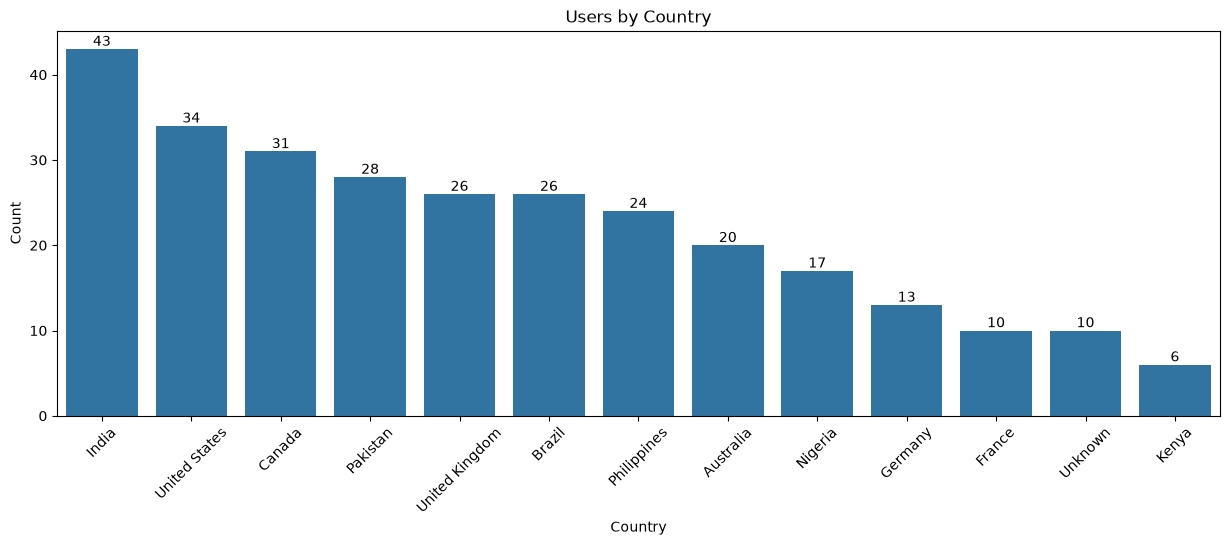

In [75]:
plt.figure(figsize=(15,5))

ax = sns.countplot(data=df, x='Country', order=df['Country'].value_counts().index)
ax.bar_label(ax.containers[0])

plt.title("Users by Country")
plt.xlabel("Country")
plt.ylabel("Count")
plt.xticks(rotation=45)

plt.savefig(IMG + "05_country.png", bbox_inches="tight")
plt.show()

In [76]:
df['Gender'].value_counts()

Gender
Male       145
Female     117
Other       16
Unknown     10
Name: count, dtype: int64

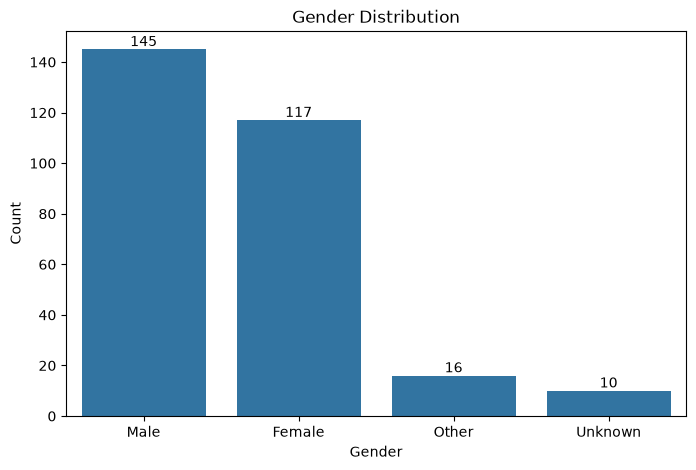

In [77]:
plt.figure(figsize=(8,5))

ax = sns.countplot(data=df, x='Gender', order=df['Gender'].value_counts().index)
ax.bar_label(ax.containers[0])

plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")

plt.savefig(IMG + "06_gender.png", bbox_inches="tight")
plt.show()

In [78]:
df['Education_Level'].value_counts()

Education_Level
Bachelor's       74
Undergraduate    63
Master's         52
High School      46
Diploma          25
PhD              16
Unknown          12
Name: count, dtype: int64

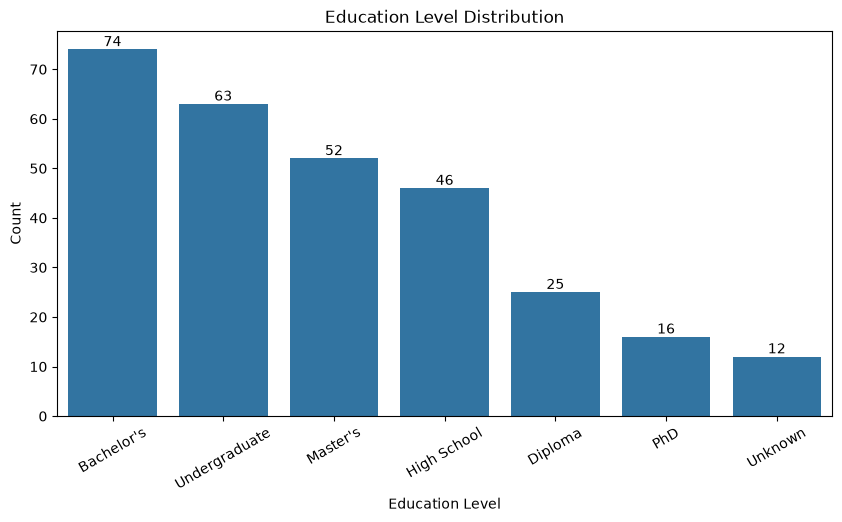

In [79]:
plt.figure(figsize=(10,5))

ax = sns.countplot(data=df, x='Education_Level', order=df['Education_Level'].value_counts().index)
ax.bar_label(ax.containers[0])

plt.title("Education Level Distribution")
plt.xlabel("Education Level")
plt.ylabel("Count")
plt.xticks(rotation=30)

plt.savefig(IMG + "07_education.png", bbox_inches="tight")
plt.show()

In [80]:
df['Would_Recommend'].value_counts()

Would_Recommend
Yes        170
No          71
Maybe       42
Unknown      5
Name: count, dtype: int64

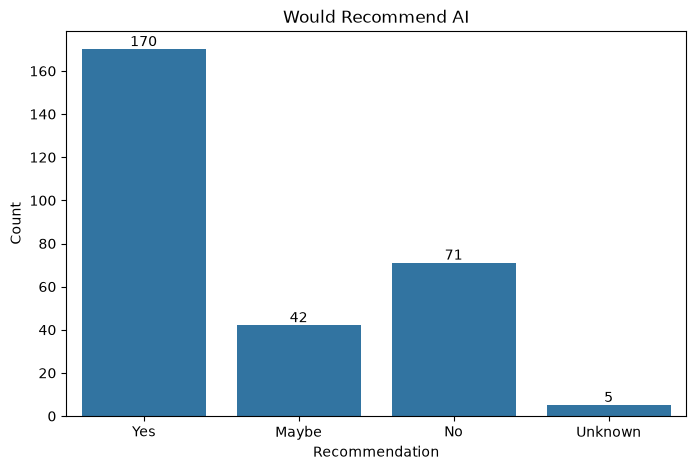

In [81]:
plt.figure(figsize=(8,5))

ax = sns.countplot(data=df, x='Would_Recommend', order=['Yes', 'Maybe', 'No', 'Unknown'])
ax.bar_label(ax.containers[0])

plt.title("Would Recommend AI")
plt.xlabel("Recommendation")
plt.ylabel("Count")

plt.savefig(IMG + "08_would_recommend.png", bbox_inches="tight")
plt.show()

# *Second: Univariate Analysis*

In [82]:
df['Age'].value_counts().sort_index()

Age
16     7
17    12
18     8
19     6
20    14
21    11
22    38
23    28
24    10
25     7
26     6
27     8
28     8
29     7
30     8
31    11
32    12
33     3
34     4
35    17
36     6
37     2
38     2
39     8
40     4
41     6
43     3
44     4
45     1
46     1
47     3
48     4
49     4
53     1
54     2
55     2
56     1
58     1
61     2
63     5
64     1
Name: count, dtype: int64

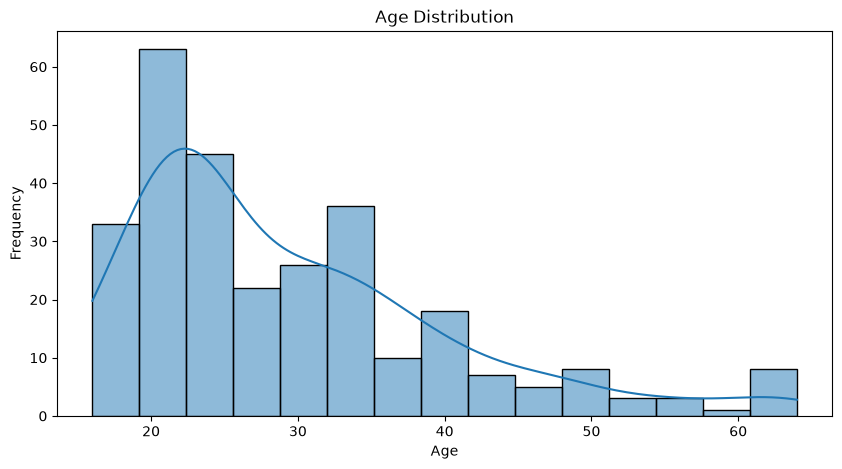

In [83]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x='Age', bins=15, kde=True)

plt.title("Age Distribution")
plt.xlabel("Age")
plt.ylabel("Frequency")

plt.savefig(IMG + "09_age.png", bbox_inches="tight")
plt.show()

Income has many zeros so log scale removes them and gives a warning, so i use `log1p` (log of 1 + income) instead.

Rows with zero income: 34


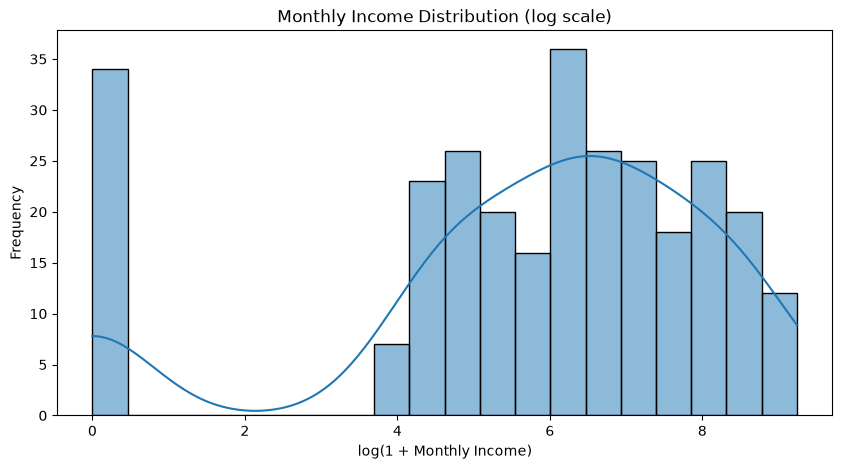

In [84]:
print("Rows with zero income:", (df['Monthly_Income'] == 0).sum())

plt.figure(figsize=(10,5))

sns.histplot(x=np.log1p(df['Monthly_Income']), bins=20, kde=True)

plt.title("Monthly Income Distribution (log scale)")
plt.xlabel("log(1 + Monthly Income)")
plt.ylabel("Frequency")

plt.savefig(IMG + "10_income.png", bbox_inches="tight")
plt.show()

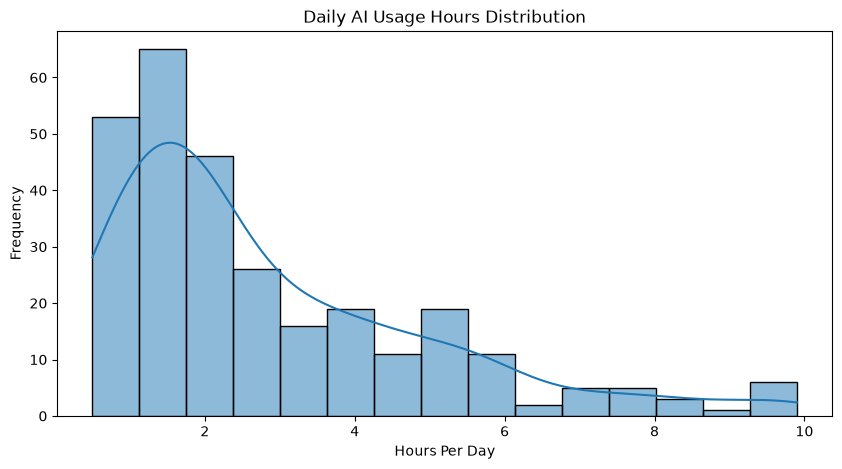

In [85]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x='AI_Usage_Hours_Per_Day', bins=15, kde=True)

plt.title("Daily AI Usage Hours Distribution")
plt.xlabel("Hours Per Day")
plt.ylabel("Frequency")

plt.savefig(IMG + "11_ai_usage_hours.png", bbox_inches="tight")
plt.show()

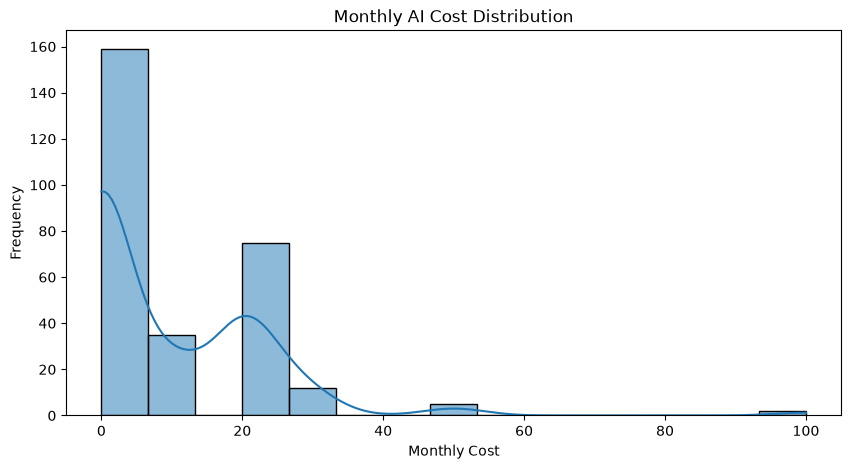

In [86]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x='Monthly_AI_Cost', bins=15, kde=True)

plt.title("Monthly AI Cost Distribution")
plt.xlabel("Monthly Cost")
plt.ylabel("Frequency")

plt.savefig(IMG + "12_ai_cost.png", bbox_inches="tight")
plt.show()

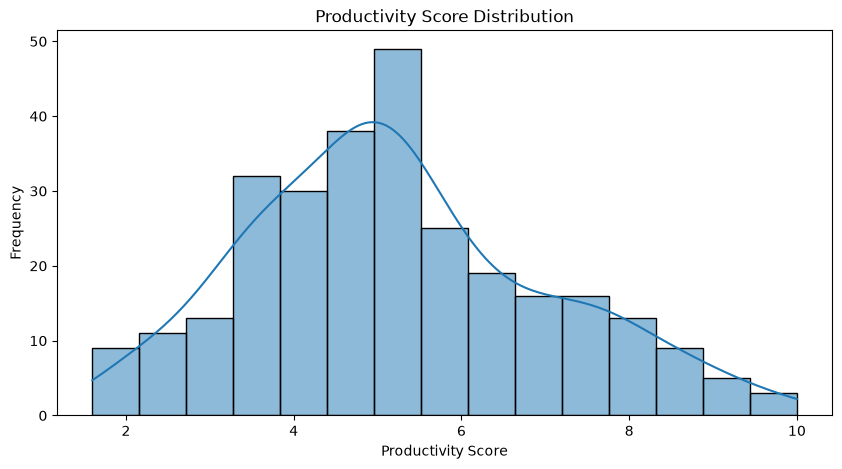

In [87]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x='Productivity_Score', bins=15, kde=True)

plt.title("Productivity Score Distribution")
plt.xlabel("Productivity Score")
plt.ylabel("Frequency")

plt.savefig(IMG + "13_productivity.png", bbox_inches="tight")
plt.show()

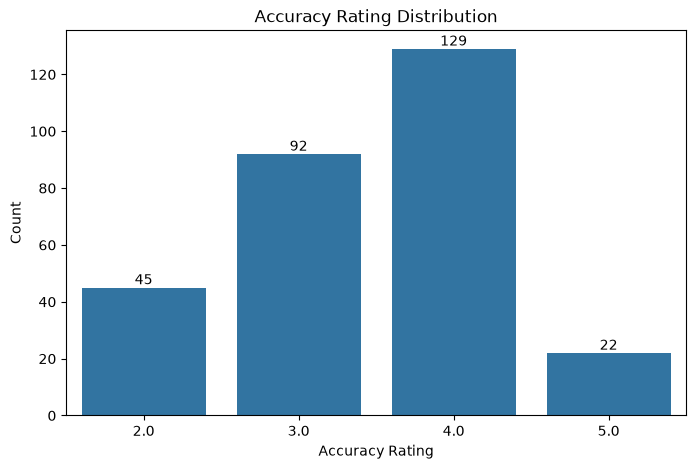

In [88]:
plt.figure(figsize=(8,5))

ax = sns.countplot(data=df, x='Accuracy_Rating')
ax.bar_label(ax.containers[0])

plt.title("Accuracy Rating Distribution")
plt.xlabel("Accuracy Rating")
plt.ylabel("Count")

plt.savefig(IMG + "14_accuracy.png", bbox_inches="tight")
plt.show()

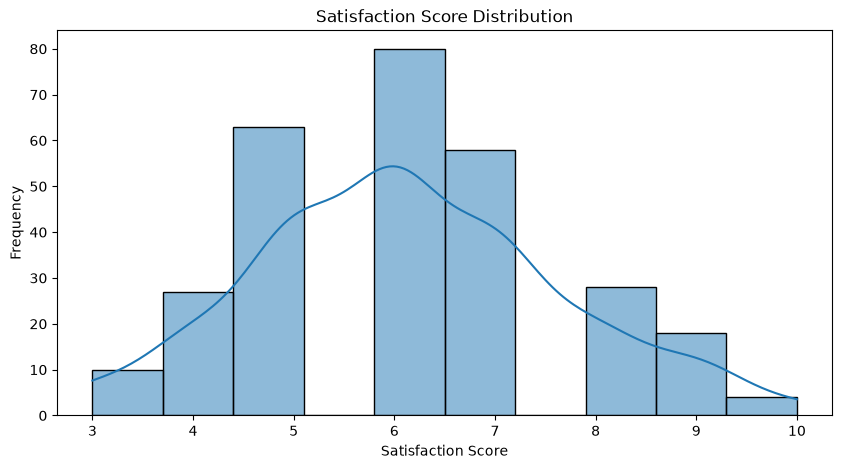

In [89]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x='Satisfaction_Score', bins=10, kde=True)

plt.title("Satisfaction Score Distribution")
plt.xlabel("Satisfaction Score")
plt.ylabel("Frequency")

plt.savefig(IMG + "15_satisfaction.png", bbox_inches="tight")
plt.show()

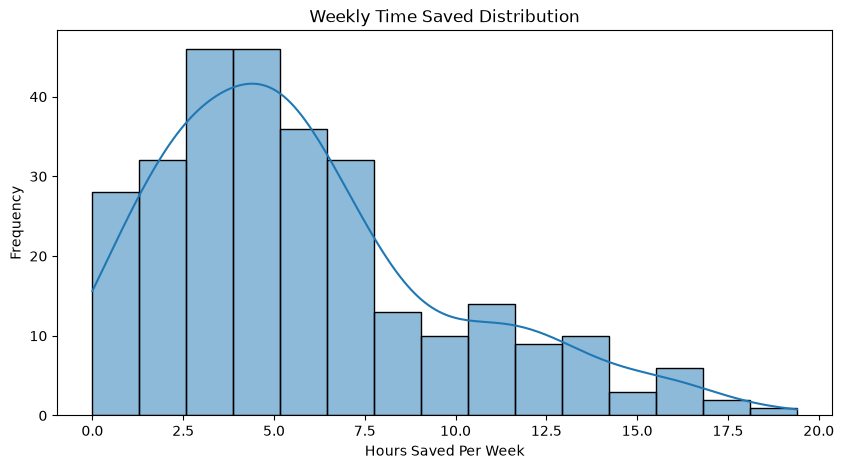

In [90]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x='Time_Saved_Hours_Per_Week', bins=15, kde=True)

plt.title("Weekly Time Saved Distribution")
plt.xlabel("Hours Saved Per Week")
plt.ylabel("Frequency")

plt.savefig(IMG + "16_time_saved.png", bbox_inches="tight")
plt.show()

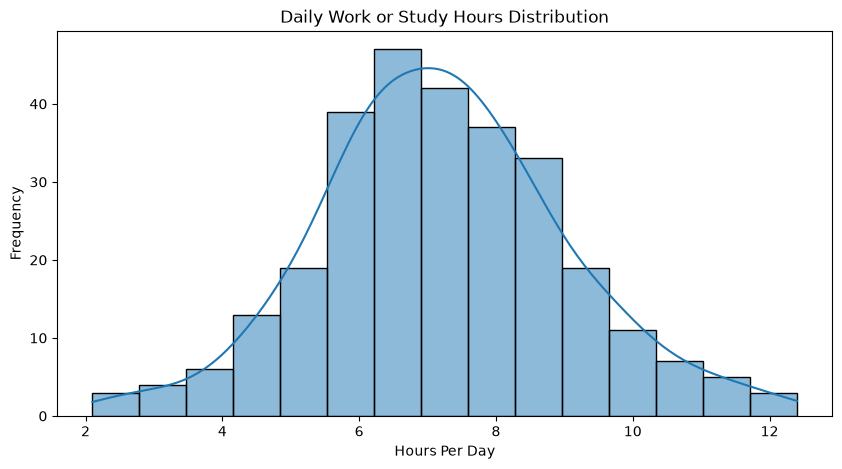

In [91]:
plt.figure(figsize=(10,5))

sns.histplot(data=df, x='Work_or_Study_Hours_Per_Day', bins=15, kde=True)

plt.title("Daily Work or Study Hours Distribution")
plt.xlabel("Hours Per Day")
plt.ylabel("Frequency")

plt.savefig(IMG + "17_work_study_hours.png", bbox_inches="tight")
plt.show()

Quick look for outliers in the main numeric columns

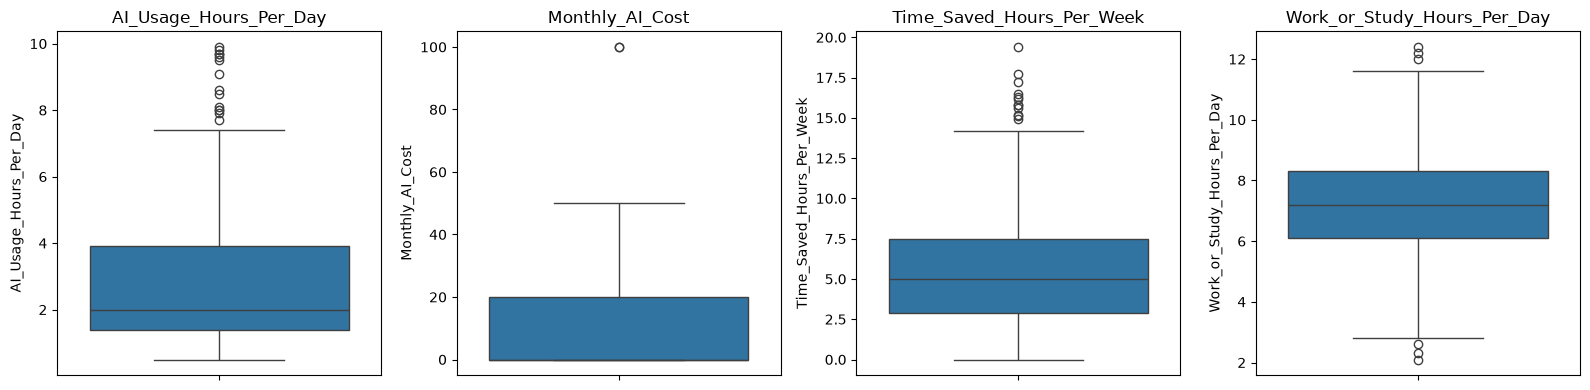

In [92]:
outlier_cols = [
    'AI_Usage_Hours_Per_Day',
    'Monthly_AI_Cost',
    'Time_Saved_Hours_Per_Week',
    'Work_or_Study_Hours_Per_Day'
]

fig, axes = plt.subplots(1, 4, figsize=(16,4))

for ax, col in zip(axes, outlier_cols):
    sns.boxplot(data=df, y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.savefig(IMG + "18_outliers_boxplot.png", bbox_inches="tight")
plt.show()

# *Third: Bivariate Analysis*

## *AI Usage vs Productivity*

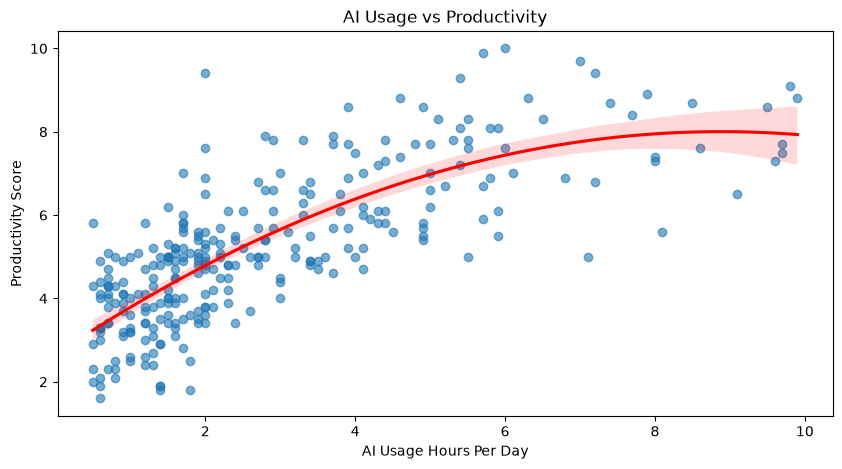

In [93]:
plt.figure(figsize=(10,5))

# order=2 because the points look like they flatten after some hours, a straight line is not perfect
sns.regplot(
    data=df,
    x='AI_Usage_Hours_Per_Day',
    y='Productivity_Score',
    order=2,
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title("AI Usage vs Productivity")
plt.xlabel("AI Usage Hours Per Day")
plt.ylabel("Productivity Score")

plt.savefig(IMG + "19_usage_vs_productivity.png", bbox_inches="tight")
plt.show()

In [94]:
print("Pearson :", round(df['AI_Usage_Hours_Per_Day'].corr(df['Productivity_Score']), 3))
print("Spearman:", round(df['AI_Usage_Hours_Per_Day'].corr(df['Productivity_Score'], method='spearman'), 3))

Pearson : 0.75
Spearman: 0.781


## *AI Usage vs Time Saved*

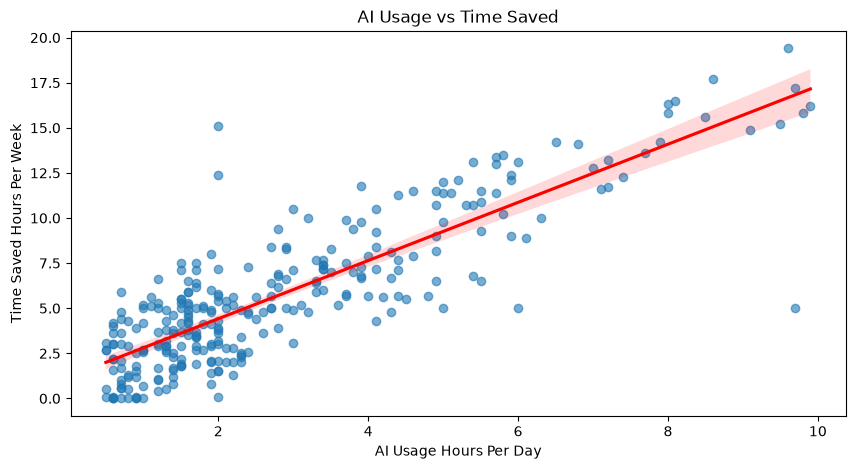

In [95]:
plt.figure(figsize=(10,5))

sns.regplot(
    data=df,
    x='AI_Usage_Hours_Per_Day',
    y='Time_Saved_Hours_Per_Week',
    scatter_kws={'alpha': 0.6},
    line_kws={'color': 'red'}
)

plt.title("AI Usage vs Time Saved")
plt.xlabel("AI Usage Hours Per Day")
plt.ylabel("Time Saved Hours Per Week")

plt.savefig(IMG + "20_usage_vs_time_saved.png", bbox_inches="tight")
plt.show()

In [96]:
print("Pearson :", round(df['AI_Usage_Hours_Per_Day'].corr(df['Time_Saved_Hours_Per_Week']), 3))
print("Spearman:", round(df['AI_Usage_Hours_Per_Day'].corr(df['Time_Saved_Hours_Per_Week'], method='spearman'), 3))

Pearson : 0.849
Spearman: 0.793


## *Correlation Between All Numeric Columns*

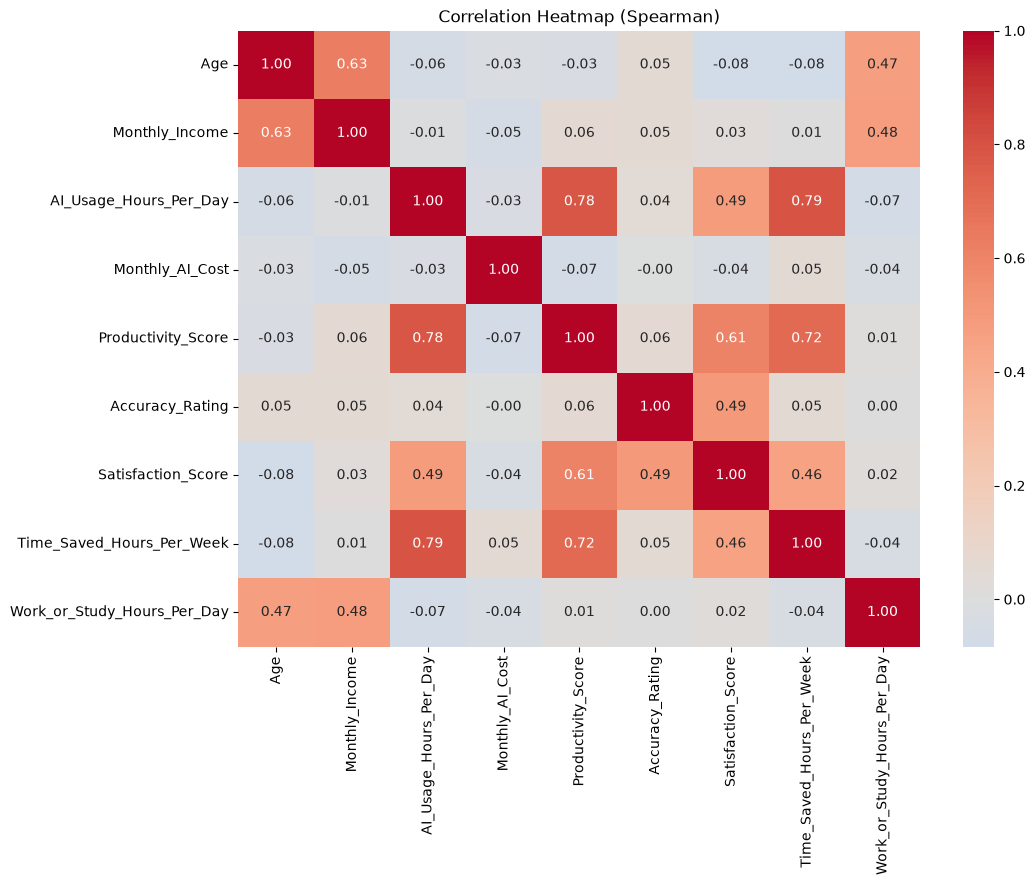

In [97]:
num_cols = [
    'Age', 'Monthly_Income', 'AI_Usage_Hours_Per_Day', 'Monthly_AI_Cost',
    'Productivity_Score', 'Accuracy_Rating', 'Satisfaction_Score',
    'Time_Saved_Hours_Per_Week', 'Work_or_Study_Hours_Per_Day'
]

plt.figure(figsize=(11,8))

# spearman because accuracy/satisfaction are ratings and some columns are skewed
sns.heatmap(df[num_cols].corr(method='spearman'), annot=True, fmt=".2f", cmap="coolwarm", center=0)

plt.title("Correlation Heatmap (Spearman)")

plt.savefig(IMG + "21_correlation_heatmap.png", bbox_inches="tight")
plt.show()

## *User Type vs AI Usage*

In [98]:
df.groupby('User_Type')['AI_Usage_Hours_Per_Day'].agg(['mean', 'median', 'count'])

,mean,median,count
User_Type,,,
Professional,2.705109,2.0,137
Student,2.973510,2.0,151


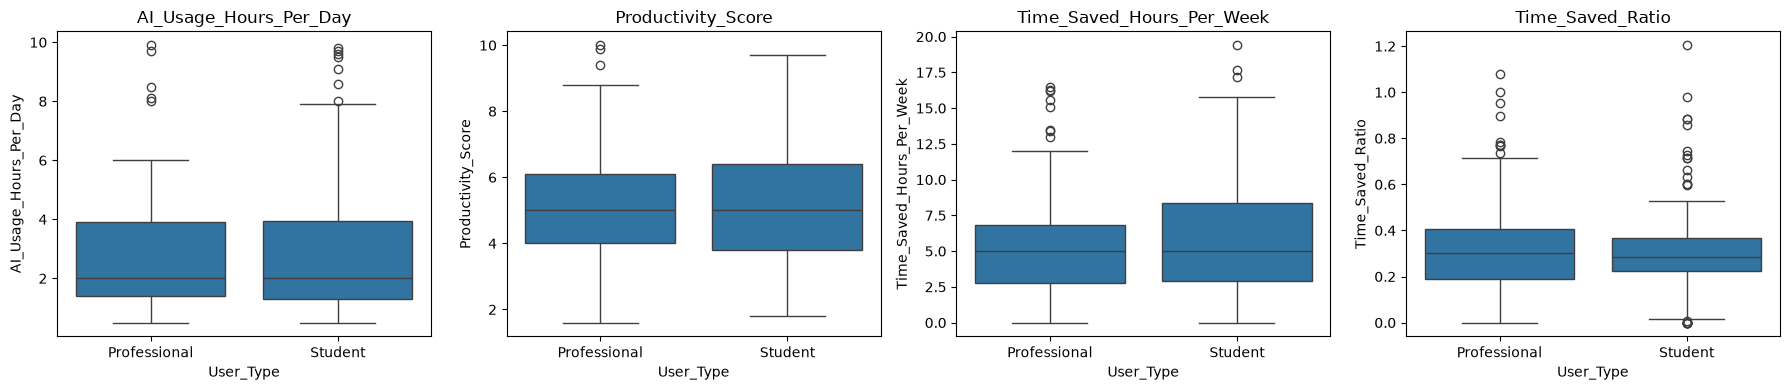

In [99]:
compare_cols = [
    'AI_Usage_Hours_Per_Day',
    'Productivity_Score',
    'Time_Saved_Hours_Per_Week',
    'Time_Saved_Ratio'
]

fig, axes = plt.subplots(1, 4, figsize=(18,4))

for ax, col in zip(axes, compare_cols):
    sns.boxplot(data=df, x='User_Type', y=col, ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.savefig(IMG + "22_user_type_comparison.png", bbox_inches="tight")
plt.show()

In [100]:
# is the usage-productivity relation the same for students and professionals?
for user_type, group in df.groupby('User_Type'):
    r = group['AI_Usage_Hours_Per_Day'].corr(group['Productivity_Score'], method='spearman')
    print(user_type, "->", round(r, 3))

Professional -> 0.775
Student -> 0.784


## *AI Tool vs Productivity*

In [101]:
tools = df[df['AI_Tool'] != 'Unknown']

tool_summary = tools.groupby('AI_Tool').agg(
    users=('User_ID', 'count'),
    avg_usage=('AI_Usage_Hours_Per_Day', 'mean'),
    avg_productivity=('Productivity_Score', 'mean'),
    avg_satisfaction=('Satisfaction_Score', 'mean'),
    avg_accuracy=('Accuracy_Rating', 'mean')
).round(2).sort_values('avg_productivity', ascending=False)

tool_summary

,users,avg_usage,avg_productivity,avg_satisfaction,avg_accuracy
AI_Tool,,,,,
DeepSeek,9,3.77,5.53,6.11,3.78
Microsoft Copilot,33,3.17,5.48,6.30,3.39
Claude,31,2.70,5.27,6.10,3.45
ChatGPT,119,2.94,5.22,6.25,3.39
Meta AI,10,2.09,5.15,6.10,3.50
Grammarly,14,2.74,5.11,6.29,3.86
Google Gemini,39,2.58,5.06,5.69,3.41
Perplexity AI,23,2.36,4.69,5.83,3.43


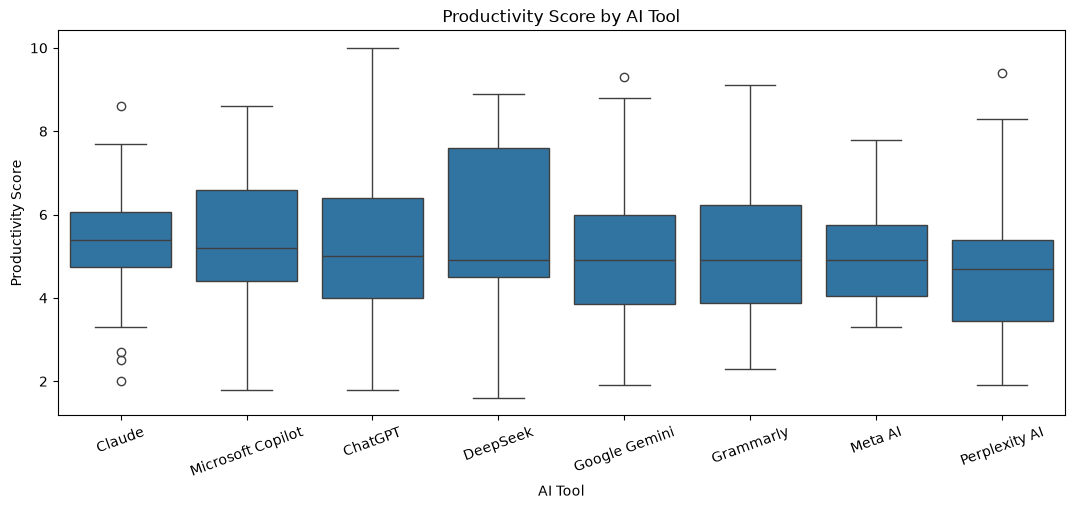

In [102]:
plt.figure(figsize=(13,5))

order = tools.groupby('AI_Tool')['Productivity_Score'].median().sort_values(ascending=False).index
sns.boxplot(data=tools, x='AI_Tool', y='Productivity_Score', order=order)

plt.title("Productivity Score by AI Tool")
plt.xlabel("AI Tool")
plt.ylabel("Productivity Score")
plt.xticks(rotation=20)

plt.savefig(IMG + "23_productivity_by_tool.png", bbox_inches="tight")
plt.show()

Note: some tools have only few users (Meta AI, DeepSeek, Grammarly), so i should not take strong conclusions from them.

## *AI Purpose vs Productivity and Time Saved*

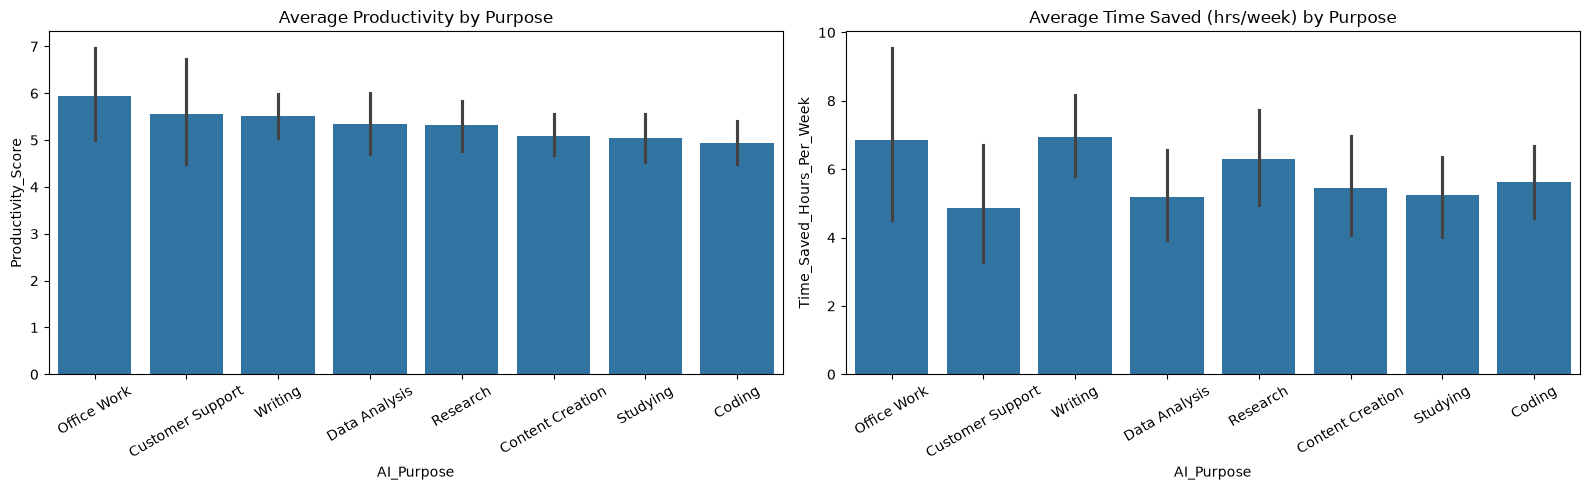

In [103]:
purpose = df[df['AI_Purpose'] != 'Unknown']

fig, axes = plt.subplots(1, 2, figsize=(16,5))

order = purpose.groupby('AI_Purpose')['Productivity_Score'].mean().sort_values(ascending=False).index

sns.barplot(data=purpose, x='AI_Purpose', y='Productivity_Score', order=order, ax=axes[0])
axes[0].set_title("Average Productivity by Purpose")
axes[0].tick_params(axis='x', rotation=30)

sns.barplot(data=purpose, x='AI_Purpose', y='Time_Saved_Hours_Per_Week', order=order, ax=axes[1])
axes[1].set_title("Average Time Saved (hrs/week) by Purpose")
axes[1].tick_params(axis='x', rotation=30)

plt.tight_layout()
plt.savefig(IMG + "24_purpose_comparison.png", bbox_inches="tight")
plt.show()

## *Paid vs Free Users*

In [104]:
df.groupby('Plan')[['AI_Usage_Hours_Per_Day', 'Productivity_Score', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week']].mean().round(2)

,AI_Usage_Hours_Per_Day,Productivity_Score,Satisfaction_Score,Time_Saved_Hours_Per_Week
Plan,,,,
Free,2.91,5.37,6.25,5.73
Paid,2.77,5.05,5.98,5.85


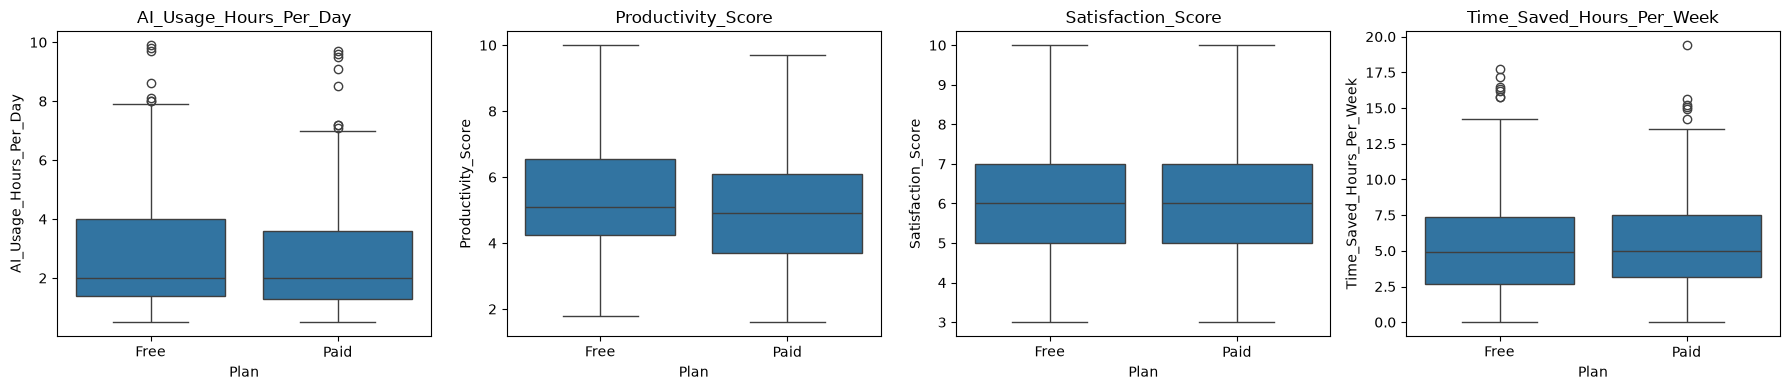

In [105]:
paid_cols = ['AI_Usage_Hours_Per_Day', 'Productivity_Score', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week']

fig, axes = plt.subplots(1, 4, figsize=(18,4))

for ax, col in zip(axes, paid_cols):
    sns.boxplot(data=df, x='Plan', y=col, order=['Free', 'Paid'], ax=ax)
    ax.set_title(col)

plt.tight_layout()
plt.savefig(IMG + "25_paid_vs_free.png", bbox_inches="tight")
plt.show()

## *Usage Level vs Productivity*

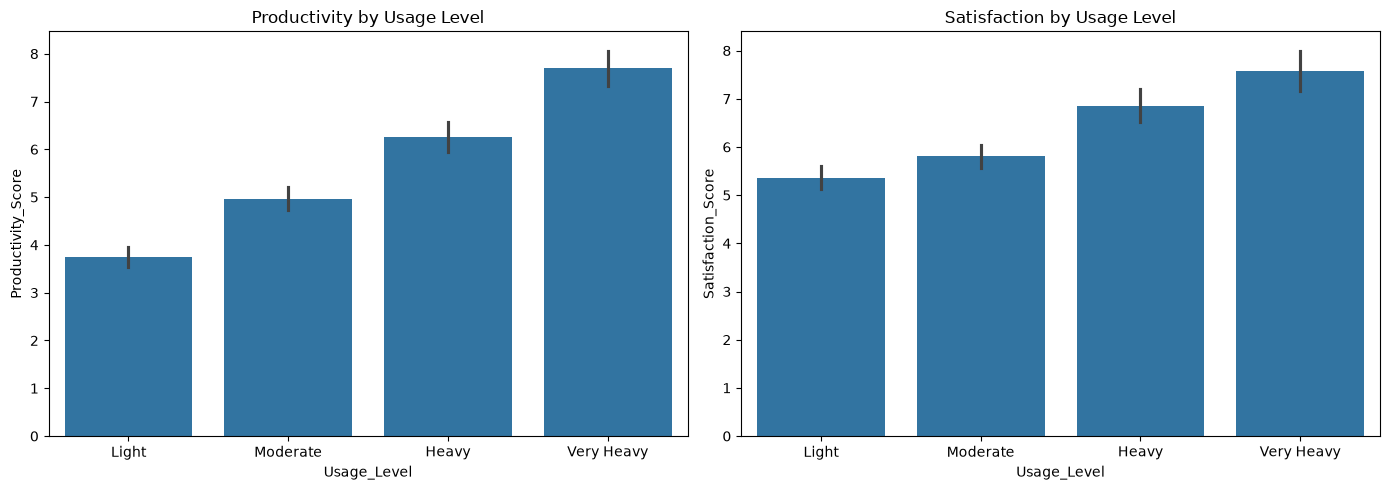

In [106]:
level_order = ['Light', 'Moderate', 'Heavy', 'Very Heavy']

fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.barplot(data=df, x='Usage_Level', y='Productivity_Score', order=level_order, ax=axes[0])
axes[0].set_title("Productivity by Usage Level")

sns.barplot(data=df, x='Usage_Level', y='Satisfaction_Score', order=level_order, ax=axes[1])
axes[1].set_title("Satisfaction by Usage Level")

plt.tight_layout()
plt.savefig(IMG + "26_usage_level.png", bbox_inches="tight")
plt.show()

In [107]:
df['Usage_Level'].value_counts()

Usage_Level
Moderate      96
Light         94
Heavy         55
Very Heavy    43
Name: count, dtype: int64

## *Satisfaction, Accuracy and Recommendation*

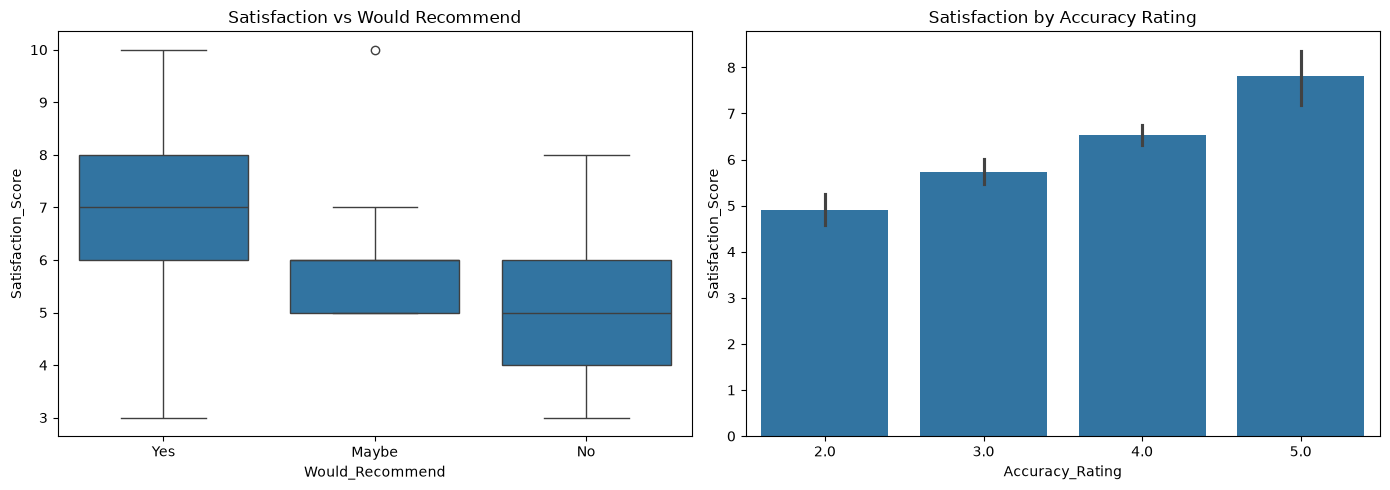

In [108]:
fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.boxplot(data=df, x='Would_Recommend', y='Satisfaction_Score', order=['Yes', 'Maybe', 'No'], ax=axes[0])
axes[0].set_title("Satisfaction vs Would Recommend")

sns.barplot(data=df, x='Accuracy_Rating', y='Satisfaction_Score', ax=axes[1])
axes[1].set_title("Satisfaction by Accuracy Rating")

plt.tight_layout()
plt.savefig(IMG + "27_satisfaction_analysis.png", bbox_inches="tight")
plt.show()

## *Age Group and Country*

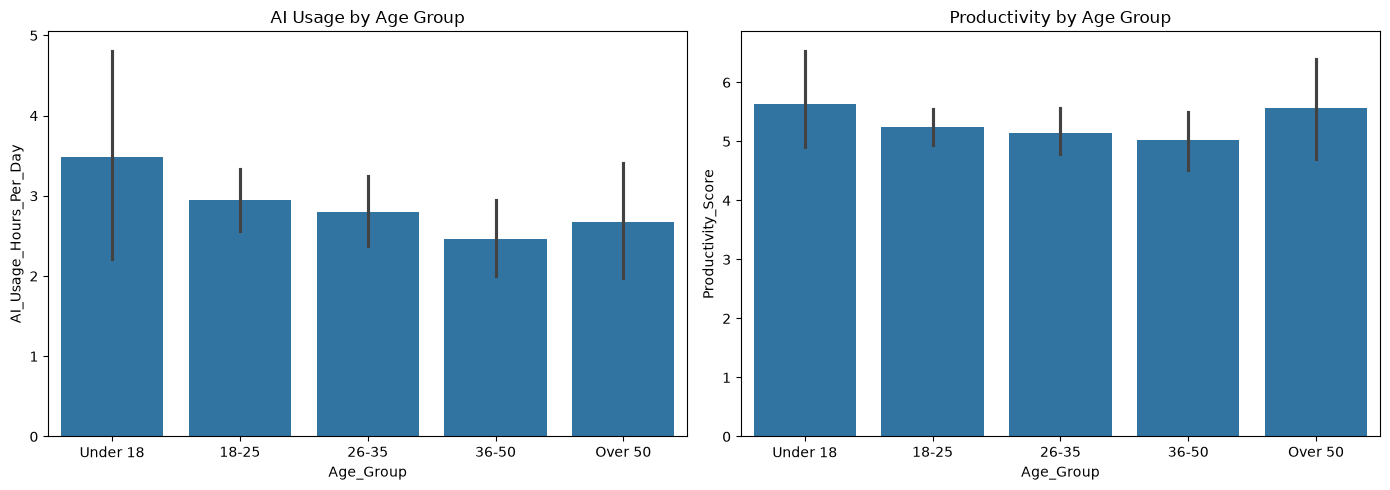

In [109]:
age_order = ['Under 18', '18-25', '26-35', '36-50', 'Over 50']

fig, axes = plt.subplots(1, 2, figsize=(14,5))

sns.barplot(data=df, x='Age_Group', y='AI_Usage_Hours_Per_Day', order=age_order, ax=axes[0])
axes[0].set_title("AI Usage by Age Group")

sns.barplot(data=df, x='Age_Group', y='Productivity_Score', order=age_order, ax=axes[1])
axes[1].set_title("Productivity by Age Group")

plt.tight_layout()
plt.savefig(IMG + "28_age_group.png", bbox_inches="tight")
plt.show()

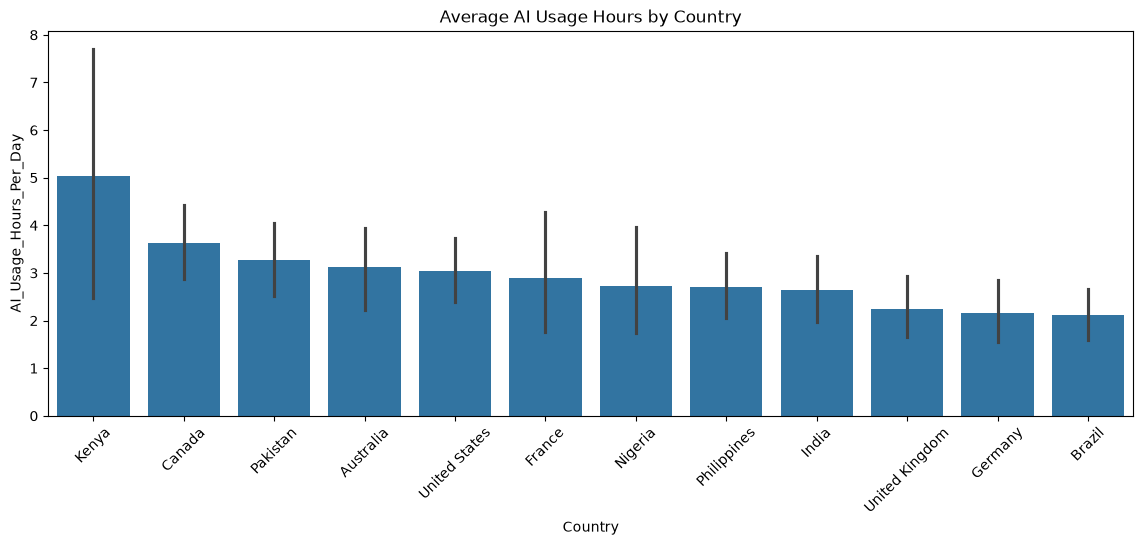

In [110]:
country_df = df[df['Country'] != 'Unknown']

plt.figure(figsize=(14,5))

order = country_df.groupby('Country')['AI_Usage_Hours_Per_Day'].mean().sort_values(ascending=False).index
sns.barplot(data=country_df, x='Country', y='AI_Usage_Hours_Per_Day', order=order)

plt.title("Average AI Usage Hours by Country")
plt.xticks(rotation=45)

plt.savefig(IMG + "29_country_usage.png", bbox_inches="tight")
plt.show()

# *Fourth: Quick Statistical Checks*

The correlations above can be just by chance, so i use simple tests (non parametric because the data is not normal).

In [111]:
students = df[df['User_Type'] == 'Student']
professionals = df[df['User_Type'] == 'Professional']

for col in ['AI_Usage_Hours_Per_Day', 'Productivity_Score', 'Time_Saved_Hours_Per_Week', 'Satisfaction_Score']:
    stat, p = stats.mannwhitneyu(students[col], professionals[col])
    print(f"{col:30s} p-value = {p:.4f}")

AI_Usage_Hours_Per_Day         p-value = 0.7525
Productivity_Score             p-value = 0.5158
Time_Saved_Hours_Per_Week      p-value = 0.5967
Satisfaction_Score             p-value = 0.6762


In [112]:
# is there a real difference in productivity between tools? (only tools with 10+ users)
groups = [g['Productivity_Score'].values for name, g in tools.groupby('AI_Tool') if len(g) >= 10]

stat, p = stats.kruskal(*groups)
print("Kruskal p-value (productivity between tools):", round(p, 4))

Kruskal p-value (productivity between tools): 0.5518


In [113]:
# paid vs free
paid = df[df['Plan'] == 'Paid']
free = df[df['Plan'] == 'Free']

for col in ['Productivity_Score', 'Satisfaction_Score', 'Time_Saved_Hours_Per_Week']:
    stat, p = stats.mannwhitneyu(paid[col], free[col])
    print(f"{col:30s} p-value = {p:.4f}")

Productivity_Score             p-value = 0.1011
Satisfaction_Score             p-value = 0.1043
Time_Saved_Hours_Per_Week      p-value = 0.4768


***Notes***
-----------------
- Usage hours has a strong positive relation with productivity and time saved, but this is only correlation. The data is self reported so heavy users may just report higher scores.
- Many missing values were filled with the median, this makes the data a little bit more "average" than the real one, so the relations may be weaker than they really are.
- The sample is small (288 users) and some groups (countries, tools) have few users, so i don't generalise from them.